# 🎮 Role 1 (Altaf) Visual Playground: Before vs. After & Final Pipeline Preview

**Purpose of This Notebook:**
1. **BEFORE (Bronze / Raw Layer):** Inspect the raw JogjaPulse CSVs & OpenStreetMap JSON + visualize the raw data pitfalls (sample discontinuities, $k < 5$ missing days, and no facility labels).
2. **AFTER (Silver Layer — Role 1 / Altaf's Deliverables):** Explore the cleaned tables, `WIB (UTC+7)` calendar flags, $\ge 90\%$ publication coverage filter, and extracted OSM facilities.
3. **FUTURE / FINAL PREVIEW (Simulated Role 2 Nalen, Role 3 Rafi, Role 4 Akhnaf):** Preview what the final **Gold Layer** analytical table and interactive visualizations look like once combined with campus, mall, hospital, market, tourism, and transit facilities.

In [1]:
import sys
import json
from pathlib import Path

# Auto-detect project root (works whether run from `notebooks/` or project root) & attach `.venv` packages if needed
PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / 'data').exists() and (PROJECT_ROOT.parent / 'data').exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

for sp in (PROJECT_ROOT / '.venv' / 'lib').glob('python*/site-packages'):
    if str(sp) not in sys.path:
        sys.path.insert(0, str(sp))

import numpy as np
import pandas as pd
import yaml
import matplotlib.pyplot as plt
import seaborn as sns
import folium
from pyproj import Transformer
from IPython.display import display

plt.style.use('seaborn-v0_8-whitegrid')
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 1000)

RAW_DIR = PROJECT_ROOT / 'data' / 'raw'
SILVER_DIR = PROJECT_ROOT / 'data' / 'silver'
print('✅ Workspace Ready:', PROJECT_ROOT)
print('✅ Python Executable:', sys.executable)

✅ Workspace Ready: /Users/altafparvesh/UniversityProject/Human-Mobility
✅ Python Executable: /Users/altafparvesh/Documents/UNIVERSITY/data Engineering/Dataset/.venv/bin/python


---
## 1️⃣ BEFORE: Raw Data Shape & Pitfalls (Bronze Layer)

**What the raw data (`presence_cell500m_daily.csv`) looks like before Role 1:**
* Contains only `cell_id`, coordinates, `date` (string), and `n_maids` (device counts).
* **No place/facility names:** We cannot tell if `E786_N18255` is UGM, a hospital, a mall, or rice fields.
* **64.6% suppressed/missing cell-days (`NaN`):** Any cell with $< 5$ devices on a given day is omitted for privacy ($k = 5$ rule).
* **Sharp Sample Discontinuities:** On **1 Jan 2022** (-34%) and **16 Feb 2022** (-68%), raw device counts drop sharply due to upstream panel changes—plus an anomalous drop on **8 Mar 2022**.

In [2]:
raw_daily = pd.read_csv(RAW_DIR / 'presence_cell500m_daily.csv')
raw_hourly = pd.read_csv(RAW_DIR / 'presence_kapanewon_hourly.csv')

print(f'📦 RAW Daily Grid: {len(raw_daily):,} rows | {raw_daily["cell_id"].nunique():,} unique cells | {raw_daily["date"].nunique()} days')
print(f'📦 RAW Hourly Kapanewon: {len(raw_hourly):,} rows | {raw_hourly["kapanewon_code"].nunique()} kapanewon')
print('\n--- First 5 Rows of RAW Daily CSV (Before Role 1 Processing) ---')
display(raw_daily.head(5))

📦 RAW Daily Grid: 183,548 rows | 5,715 unique cells | 151 days
📦 RAW Hourly Kapanewon: 230,418 rows | 78 kapanewon

--- First 5 Rows of RAW Daily CSV (Before Role 1 Processing) ---


,cell_id,x_min_utm,y_min_utm,centroid_lon,centroid_lat,date,n_maids
0,E786_N18255,393000,9127500,110.031602,-7.889900,2021-12-01,9
1,E789_N18259,394500,9129500,110.045250,-7.871843,2021-12-01,7
2,E790_N18255,395000,9127500,110.049744,-7.889942,2021-12-01,17
3,E791_N18254,395500,9127000,110.054269,-7.894474,2021-12-01,5
4,E792_N18252,396000,9126000,110.058784,-7.903529,2021-12-01,20


/var/folders/zd/5jmgjkws3g33r640xbbj2k5m0000gn/T/ipykernel_34025/1814644579.py:16: UserWarning: Glyph 9888 (\N{WARNING SIGN}) missing from font(s) Arial.
  plt.tight_layout()
/Users/altafparvesh/Documents/UNIVERSITY/data Engineering/Dataset/.venv/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 9888 (\N{WARNING SIGN}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


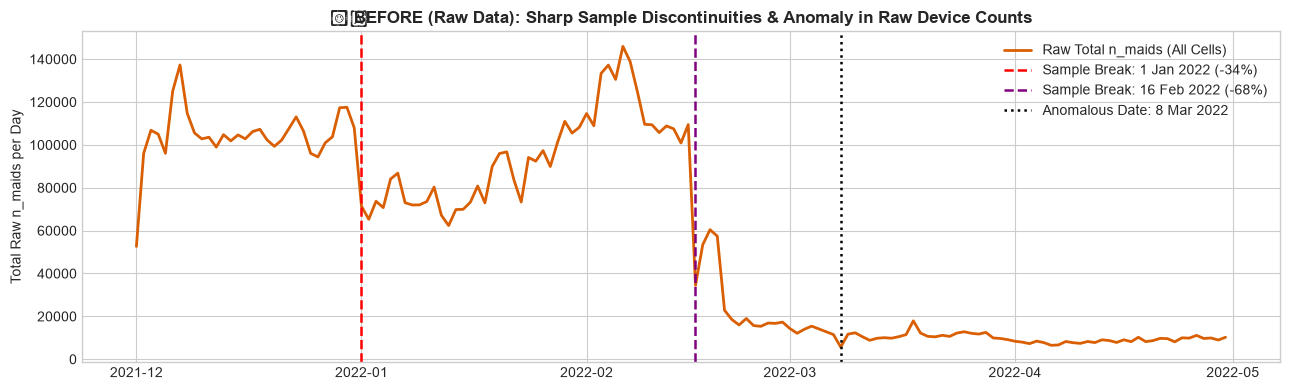

In [3]:
# Visualizing the Raw Data Pitfall: Why We Cannot Use Unnormalized Raw `n_maids`
raw_by_date = raw_daily.groupby('date', as_index=False).agg(
    total_maids=('n_maids', 'sum'),
    published_cells=('cell_id', 'count')
)
raw_by_date['date_dt'] = pd.to_datetime(raw_by_date['date'])

fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(raw_by_date['date_dt'], raw_by_date['total_maids'], color='#d95f02', lw=2, label='Raw Total n_maids (All Cells)')
ax.axvline(pd.Timestamp('2022-01-01'), color='red', ls='--', lw=1.8, label='Sample Break: 1 Jan 2022 (-34%)')
ax.axvline(pd.Timestamp('2022-02-16'), color='purple', ls='--', lw=1.8, label='Sample Break: 16 Feb 2022 (-68%)')
ax.axvline(pd.Timestamp('2022-03-08'), color='black', ls=':', lw=1.8, label='Anomalous Date: 8 Mar 2022')
ax.set_title('⚠️ BEFORE (Raw Data): Sharp Sample Discontinuities & Anomaly in Raw Device Counts', fontsize=12, fontweight='bold')
ax.set_ylabel('Total Raw n_maids per Day')
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()

---
## 2️⃣ AFTER: What We Built in Role 1 (Silver Layer)

In **Role 1 (Altaf)**, we transformed the raw inputs into **clean Silver Parquet tables (`data/silver/`) + audited OSM facility extracts (`data/raw/`)**:
1. **OSM Extraction & Landmark Audit (`osm_facilities_current.json` & `osm_landmark_audit.json`):** Extracted **2,360 OSM facilities** across DIY (Campuses, Hospitals, Malls, Markets, Tourism Sites, Transit Stops) and verified all 6 major DIY landmarks.
2. **Unique 500m Grid Coordinates (`grid_cells_unique.parquet`):** All 5,715 cells with exact $500\text{ m} \times 500\text{ m}$ UTM bounding boxes (`x_min_utm` to `y_max_utm`), ready for **Nalen (Role 2)**.
3. **Cleaned Daily Mobility Table (`mobility_daily_clean.parquet`):** Enriched from 7 columns to 29 columns with `WIB (UTC+7)` dates, `is_weekend`, `is_nataru_window`, `sampling_period`, normalized `published_presence_share_pct`, and $\ge 90\%$ coverage eligibility flags.
4. **Cell Coverage Audit (`cell_coverage_audit.parquet`):** Computes weekday and weekend publication coverage per cell across every period ($80\%, 90\%, 95\%$ thresholds) for **Rafi (Role 3)**.

In [4]:
# Inspect OSM Facility Counts & Week 1 DIY Landmark Audit
with open(RAW_DIR / 'osm_landmark_audit.json') as f:
    lm_audit = json.load(f)

cat_df = (
    pd.DataFrame(lm_audit['category_count_comparison'])
    .T[['current']]
    .rename(columns={'current': 'Extracted OSM Elements in DIY'})
)
lm_rows = []
for k, v in lm_audit['landmark_comparison_summary'].items():
    lm_rows.append({
        'DIY Landmark': k,
        'Expected Category': v['expected_category'],
        'Captured in OSM?': '✅ Yes' if v['current_captured'] else '❌ No',
        'Total Elements (Node/Way/Rel)': v['current_total_elements'],
        'Sample Names in OSM': ', '.join(v['current_names_sample'][:3])
    })
lm_df = pd.DataFrame(lm_rows)

print('🏛️ Summary of 2,360 Extracted OSM Facilities by Category:')
display(cat_df)
print('\n✅ Week 1 Audit of 6 Major DIY Landmarks:')
display(lm_df)

🏛️ Summary of 2,360 Extracted OSM Facilities by Category:


,Extracted OSM Elements in DIY
education_campus,189
healthcare_hospital,186
commercial_mall,33
traditional_market,375
tourism_site,537
transit_hub,1039



✅ Week 1 Audit of 6 Major DIY Landmarks:


,DIY Landmark,Expected Category,Captured in OSM?,Total Elements (Node/Way/Rel),Sample Names in OSM
0,UGM,education_campus,✅ Yes,48,"Balairung UGM, Bundaran UGM, Fakultas Ekonomik..."
1,UNY,education_campus,✅ Yes,31,"Asrama Mahasiswa UNY Kampus Wates, FIP UNY, Fa..."
2,Ambarrukmo_Plaza,commercial_mall,✅ Yes,7,"Ambarrukmo Plaza 1, Ambarrukmo Plaza 2, Halte ..."
3,Pakuwon_Hartono_Mall,commercial_mall,✅ Yes,8,"Halte Pakuwon Mall Jogja, Pakuwon Mall, Pakuwo..."
4,RSUP_Dr_Sardjito,healthcare_hospital,✅ Yes,8,"Halte RS Sardjito (Barat), Halte RS Sardjito (..."
5,Malioboro,tourism_site / commercial_mall,✅ Yes,16,"Halte Malioboro 1, Halte Malioboro 2, Jalan Ma..."


In [5]:
# Compare BEFORE vs. AFTER Table Schema (`mobility_daily_clean.parquet`)
silver_daily = pd.read_parquet(SILVER_DIR / 'mobility_daily_clean.parquet')
silver_cells = pd.read_parquet(SILVER_DIR / 'grid_cells_unique.parquet')
silver_cov = pd.read_parquet(SILVER_DIR / 'cell_coverage_audit.parquet')

print(f'✨ AFTER Silver Daily Shape: {silver_daily.shape[0]:,} rows x {silver_daily.shape[1]} columns (expanded from 7 raw columns!)')
cols_to_show = [
    'cell_id', 'date', 'n_maids', 'day_name', 'is_weekend',
    'is_nataru_window', 'sampling_period', 'pass_90_in_period',
    'published_presence_share_pct', 'published_presence_share_common90_pct'
]
display(silver_daily[cols_to_show].head(6))

✨ AFTER Silver Daily Shape: 183,548 rows x 50 columns (expanded from 7 raw columns!)


,cell_id,date,n_maids,day_name,is_weekend,is_nataru_window,sampling_period,pass_90_in_period,published_presence_share_pct,published_presence_share_common90_pct
0,E786_N18255,2021-12-01,9,Wednesday,False,False,2021_Dec,False,0.017109,NaN
1,E789_N18259,2021-12-01,7,Wednesday,False,False,2021_Dec,False,0.013307,NaN
2,E790_N18255,2021-12-01,17,Wednesday,False,False,2021_Dec,False,0.032318,NaN
3,E791_N18254,2021-12-01,5,Wednesday,False,False,2021_Dec,False,0.009505,NaN
4,E792_N18252,2021-12-01,20,Wednesday,False,False,2021_Dec,True,0.038021,NaN
5,E792_N18253,2021-12-01,14,Wednesday,False,False,2021_Dec,False,0.026614,NaN


/var/folders/zd/5jmgjkws3g33r640xbbj2k5m0000gn/T/ipykernel_34025/2606876698.py:30: UserWarning: Glyph 10024 (\N{SPARKLES}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/zd/5jmgjkws3g33r640xbbj2k5m0000gn/T/ipykernel_34025/2606876698.py:30: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) Arial.
  plt.tight_layout()
/Users/altafparvesh/Documents/UNIVERSITY/data Engineering/Dataset/.venv/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 10024 (\N{SPARKLES}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/altafparvesh/Documents/UNIVERSITY/data Engineering/Dataset/.venv/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


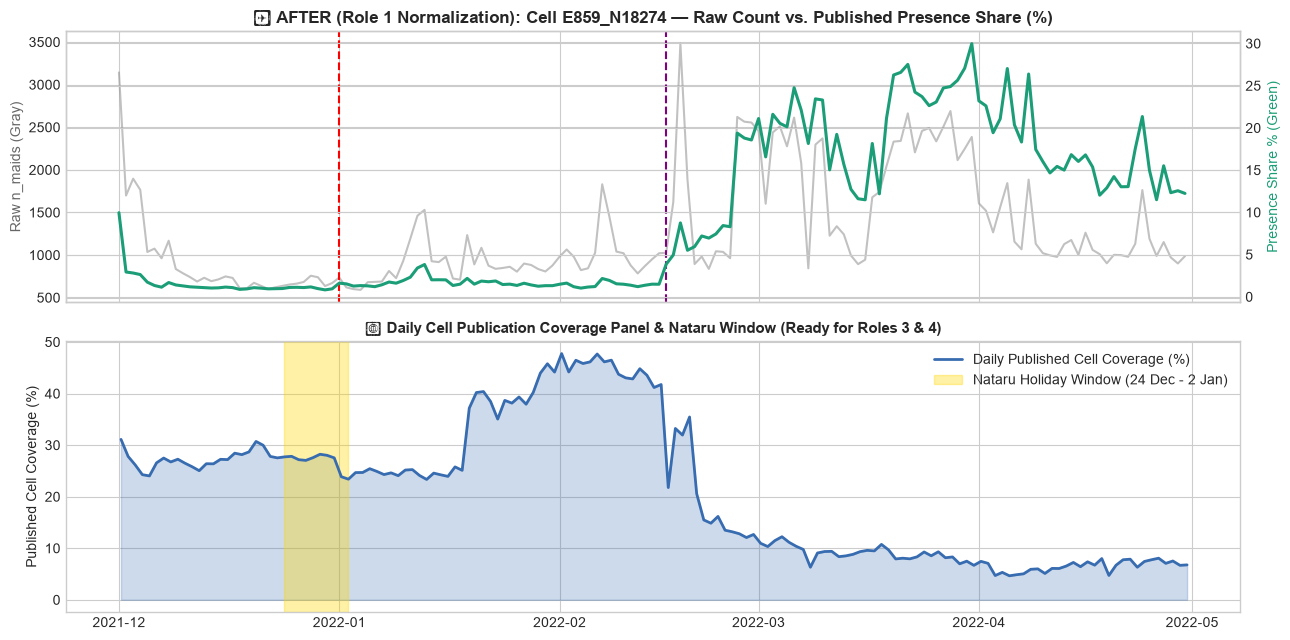

In [6]:
# Visualizing AFTER: How `Published Presence Share (%)` Stabilizes the Sample Breaks
daily_sum = pd.read_parquet(SILVER_DIR / 'daily_coverage_summary.parquet')
daily_sum['date_dt'] = pd.to_datetime(daily_sum['date'])

# Pick the busiest well-covered cell in DIY
top_cell_id = silver_daily.groupby('cell_id')['n_maids'].median().idxmax()
cell_ts = silver_daily[silver_daily['cell_id'] == top_cell_id].sort_values('date_wib')

fig, axes = plt.subplots(2, 1, figsize=(13, 6.5), sharex=True)

# Top Panel: Raw n_maids vs. Normalized Presence Share (%)
ax1 = axes[0]
ax1_twin = ax1.twinx()
ax1.plot(cell_ts['date_wib'], cell_ts['n_maids'], color='#999999', alpha=0.6, lw=1.5, label='BEFORE: Raw n_maids (Drops at Sample Breaks)')
ax1_twin.plot(cell_ts['date_wib'], cell_ts['published_presence_share_common90_pct'], color='#1b9e77', lw=2.2, label='AFTER: Normalized Presence Share % (Stable!)')
ax1.axvline(pd.Timestamp('2022-01-01', tz='Asia/Jakarta'), color='red', ls='--')
ax1.axvline(pd.Timestamp('2022-02-16', tz='Asia/Jakarta'), color='purple', ls='--')
ax1.set_title(f'✨ AFTER (Role 1 Normalization): Cell {top_cell_id} — Raw Count vs. Published Presence Share (%)', fontsize=12, fontweight='bold')
ax1.set_ylabel('Raw n_maids (Gray)', color='#666666')
ax1_twin.set_ylabel('Presence Share % (Green)', color='#1b9e77')

# Bottom Panel: Daily Publication Coverage % + Nataru Holiday Window
ax2 = axes[1]
ax2.fill_between(daily_sum['date_dt'], daily_sum['daily_cell_coverage_pct'], color='#386cb0', alpha=0.25)
ax2.plot(daily_sum['date_dt'], daily_sum['daily_cell_coverage_pct'], color='#386cb0', lw=2, label='Daily Published Cell Coverage (%)')
ax2.axvspan(pd.Timestamp('2021-12-24'), pd.Timestamp('2022-01-02'), color='gold', alpha=0.35, label='Nataru Holiday Window (24 Dec - 2 Jan)')
ax2.set_ylabel('Published Cell Coverage (%)')
ax2.set_title('📊 Daily Cell Publication Coverage Panel & Nataru Window (Ready for Roles 3 & 4)', fontsize=11, fontweight='bold')
ax2.legend(loc='upper right')
plt.tight_layout()
plt.show()

/var/folders/zd/5jmgjkws3g33r640xbbj2k5m0000gn/T/ipykernel_34025/1463221145.py:16: UserWarning: Glyph 128737 (\N{SHIELD}) missing from font(s) Arial.
  plt.tight_layout()
/Users/altafparvesh/Documents/UNIVERSITY/data Engineering/Dataset/.venv/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 128737 (\N{SHIELD}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


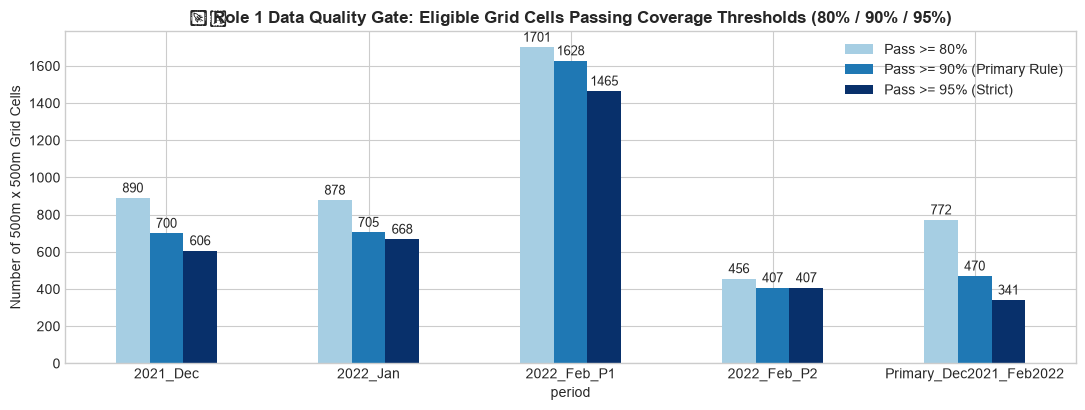

In [7]:
# Visualizing Number of Cells Passing 80%, 90%, and 95% Coverage Across Sampling Periods
periods_order = ['2021_Dec', '2022_Jan', '2022_Feb_P1', '2022_Feb_P2', 'Primary_Dec2021_Feb2022']
cov_summary = (
    silver_cov[silver_cov['period'].isin(periods_order)]
    .groupby('period')[['pass_80_ordinary', 'pass_90_ordinary', 'pass_95_ordinary']]
    .sum()
    .reindex(periods_order)
)

ax = cov_summary.plot(kind='bar', figsize=(11, 4.2), color=['#a6cee3', '#1f78b4', '#08306b'], rot=0)
ax.set_title('🛡️ Role 1 Data Quality Gate: Eligible Grid Cells Passing Coverage Thresholds (80% / 90% / 95%)', fontsize=12, fontweight='bold')
ax.set_ylabel('Number of 500m x 500m Grid Cells')
ax.legend(['Pass >= 80%', 'Pass >= 90% (Primary Rule)', 'Pass >= 95% (Strict)'])
for container in ax.containers:
    ax.bar_label(container, fontsize=9, padding=2)
plt.tight_layout()
plt.show()

---
## 3️⃣ END-TO-END FINAL PREVIEW (Simulated Role 2, Role 3, & Role 4)

Here is how our Role 1 Silver outputs will be consumed downstream to produce the final project deliverables:
* **Role 2 (Nalen):** Spatially joins `grid_cells_unique.parquet` + `osm_facilities_current.json` in `EPSG:32749` $\rightarrow$ outputs `grid_facilities.parquet` (which cells contain campuses, hospitals, malls, markets, tourism sites, or transit stops).
* **Role 3 (Rafi):** Joins Nalen's facility table with our `mobility_daily_clean.parquet` $\rightarrow$ computes **Weekday-to-Weekend Ratios (H1–H3)** and **Nataru Holiday Shockwave** (`cell_metrics.parquet`).
* **Role 4 (Akhnaf):** Renders the **4 Core Visuals** (Interactive Folium Map, Weekday/Weekend Ratio Bar Chart, Nataru Time-Series, and 24-Hour Kapanewon Diurnal Heatmap).

Below is a **working prototype using our real data** so you can inspect the expected **Gold Layer table** and final visuals right now:

In [8]:
# 🔮 PROTOTYPE OF ROLE 2 & ROLE 3: Spatial Join of OSM Facilities to 500m Grid + Weekday/Weekend Ratio
with open(RAW_DIR / 'osm_facilities_current.json') as f:
    osm_data = json.load(f)['elements']

with open(PROJECT_ROOT / 'configs' / 'osm_tags.yaml') as f:
    fac_rules = yaml.safe_load(f)['facility_categories']

# Extract point/centroid coordinates from each OSM facility
osm_pts = []
for el in osm_data:
    tags = el.get('tags', {})
    lat = el.get('lat') or (np.mean([p['lat'] for p in el['geometry']]) if 'geometry' in el and el['geometry'] else None)
    lon = el.get('lon') or (np.mean([p['lon'] for p in el['geometry']]) if 'geometry' in el and el['geometry'] else None)
    if lat is None or lon is None:
        continue
    for cat, rules in fac_rules.items():
        if any(tags.get(k) in v for k, v in rules.items()):
            osm_pts.append({'osm_id': f"{el['type']}/{el['id']}", 'name': tags.get('name', 'Unnamed'), 'category': cat, 'lat': lat, 'lon': lon})
osm_df = pd.DataFrame(osm_pts)

# Project to UTM Zone 49S (EPSG:32749) & assign to 500m grid cells (Role 2 Prototype)
tr = Transformer.from_crs('EPSG:4326', 'EPSG:32749', always_xy=True)
osm_df['x_utm'], osm_df['y_utm'] = tr.transform(osm_df['lon'].values, osm_df['lat'].values)
osm_df['x_min_utm'] = (np.floor(osm_df['x_utm'] / 500.0) * 500).astype(int)
osm_df['y_min_utm'] = (np.floor(osm_df['y_utm'] / 500.0) * 500).astype(int)

cell_fac = (
    silver_cells.merge(osm_df, on=['x_min_utm', 'y_min_utm'], how='inner')
    .groupby('cell_id', as_index=False)
    .agg(
        n_facilities=('osm_id', 'nunique'),
        n_categories=('category', 'nunique'),
        primary_category=('category', lambda s: s.mode().iloc[0]),
        sample_facility_names=('name', lambda s: ', '.join(sorted(set(s))[:3]))
    )
)
cell_fac['land_use_class'] = np.where(cell_fac['n_categories'] == 1, 'Single-Category', 'Mixed-Use')

# Compute Gold Metrics on Cells Passing >= 90% Coverage in the Primary Window (Role 3 Prototype)
prim_mob = silver_daily[
    silver_daily['is_primary_window']
    & silver_daily['pass_90_primary_window']
    & silver_daily['is_ordinary_day']
]
wd_we = (
    prim_mob.groupby(['cell_id', 'is_weekend'], as_index=False)['published_presence_share_common90_pct']
    .mean()
    .pivot(index='cell_id', columns='is_weekend', values='published_presence_share_common90_pct')
    .rename(columns={False: 'mean_weekday_share_pct', True: 'mean_weekend_share_pct'})
    .reset_index()
)
wd_we['weekday_weekend_ratio'] = wd_we['mean_weekday_share_pct'] / wd_we['mean_weekend_share_pct']

gold_preview = (
    silver_cells[['cell_id', 'centroid_lat', 'centroid_lon']]
    .merge(wd_we, on='cell_id', how='inner')
    .merge(cell_fac, on='cell_id', how='left')
)
gold_preview['primary_category'] = gold_preview['primary_category'].fillna('no_selected_facility_mapped')
gold_preview['land_use_class'] = gold_preview['land_use_class'].fillna('Baseline (No Selected Facility)')
gold_preview['sample_facility_names'] = gold_preview['sample_facility_names'].fillna('-')

print('🏆 EXPECTED FINAL GOLD TABLE PREVIEW (Combined Role 1 + Role 2 + Role 3):')
display(gold_preview[gold_preview['primary_category'] != 'no_selected_facility_mapped'].sort_values('weekday_weekend_ratio', ascending=False).head(10))

🏆 EXPECTED FINAL GOLD TABLE PREVIEW (Combined Role 1 + Role 2 + Role 3):


,cell_id,centroid_lat,centroid_lon,mean_weekday_share_pct,mean_weekend_share_pct,weekday_weekend_ratio,n_facilities,n_categories,primary_category,sample_facility_names,land_use_class
384,E870_N18282,-7.768499,110.412764,0.123300,0.077980,1.581181,1.0,1.0,education_campus,STIE YKPN,Single-Category
246,E864_N18278,-7.786550,110.385531,0.175997,0.123410,1.426118,2.0,1.0,education_campus,"AA YKPN, Institut Sains dan Teknologi AKPRIND",Single-Category
69,E853_N18273,-7.809088,110.335614,0.075965,0.055931,1.358175,1.0,1.0,tourism_site,Patung Semar Kalibayem,Single-Category
201,E861_N18282,-7.768440,110.371954,0.113176,0.085180,1.328678,10.0,3.0,healthcare_hospital,"Departemen Teknik Nuklir dan Teknik Fisika, Ha...",Mixed-Use
194,E861_N18275,-7.800098,110.371907,0.469799,0.354059,1.326893,2.0,1.0,transit_hub,Halte Museum Biologi,Single-Category
385,E870_N18283,-7.763976,110.412770,0.771598,0.581578,1.326731,7.0,1.0,education_campus,"Gedung ALD, Gedung ALE, Gedung Dekanat Fak. Pe...",Single-Category
268,E865_N18271,-7.818215,110.390020,0.137701,0.106639,1.291275,5.0,1.0,transit_hub,"Jl. Perintis Kemerdekaan, TPB Gambiran 1, TPB ...",Single-Category
226,E863_N18277,-7.791066,110.380990,0.484707,0.380698,1.273207,3.0,1.0,transit_hub,"TPB Tarumartani, Unnamed",Single-Category
238,E864_N18270,-7.822731,110.385478,0.043380,0.034452,1.259152,1.0,1.0,education_campus,Universitas Ahmad Dahlan Kampus 2,Single-Category
273,E865_N18276,-7.795602,110.390053,0.075068,0.060208,1.246814,2.0,2.0,education_campus,"F. Hukum Univ. Janabadra', RS Happy Land",Mixed-Use


/Users/altafparvesh/UniversityProject/Human-Mobility/.venv/lib/python3.14/site-packages/seaborn/utils.py:61: UserWarning: Glyph 127919 (\N{DIRECT HIT}) missing from font(s) Arial.
  fig.canvas.draw()
/var/folders/zd/5jmgjkws3g33r640xbbj2k5m0000gn/T/ipykernel_34025/2556278307.py:36: UserWarning: Glyph 128293 (\N{FIRE}) missing from font(s) Arial.
  plt.tight_layout()
/Users/altafparvesh/Documents/UNIVERSITY/data Engineering/Dataset/.venv/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 127919 (\N{DIRECT HIT}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/altafparvesh/Documents/UNIVERSITY/data Engineering/Dataset/.venv/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 128293 (\N{FIRE}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


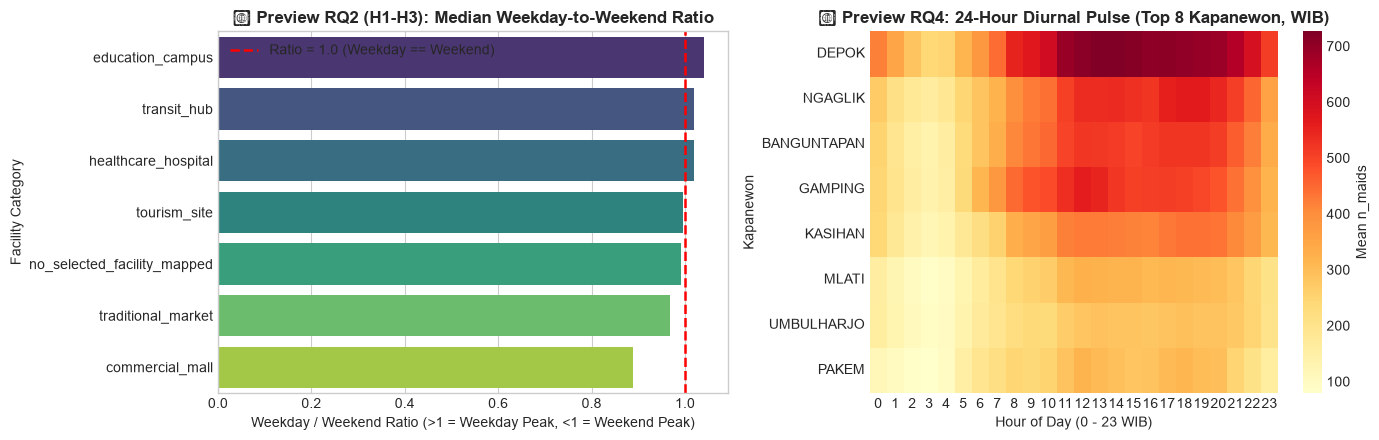

In [9]:
# 📊 FINAL VISUALIZATION PREVIEW (Roles 3 & 4): Weekday/Weekend Ratio by Category & 24-Hour Diurnal Heatmap
cat_summary = (
    gold_preview.groupby('primary_category', as_index=False)
    .agg(
        n_cells=('cell_id', 'count'),
        median_wd_we_ratio=('weekday_weekend_ratio', 'median'),
        mean_wd_we_ratio=('weekday_weekend_ratio', 'mean'),
        median_share_pct=('mean_weekday_share_pct', 'median')
    )
    .sort_values('median_wd_we_ratio', ascending=False)
)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# Left Chart: Weekday-to-Weekend Ratio (H1 Education > 1.0 vs. Tourism/Mall < 1.0)
sns.barplot(data=cat_summary, y='primary_category', x='median_wd_we_ratio', hue='primary_category', palette='viridis', legend=False, ax=axes[0])
axes[0].axvline(1.0, color='red', ls='--', lw=1.8, label='Ratio = 1.0 (Weekday == Weekend)')
axes[0].set_title('🎯 Preview RQ2 (H1-H3): Median Weekday-to-Weekend Ratio', fontweight='bold')
axes[0].set_xlabel('Weekday / Weekend Ratio (>1 = Weekday Peak, <1 = Weekend Peak)')
axes[0].set_ylabel('Facility Category')
axes[0].legend()

# Right Chart: 24-Hour Diurnal Heatmap of Top 8 Busiest Kapanewon (RQ4 — from Our Silver Hourly Table!)
silver_hr = pd.read_parquet(SILVER_DIR / 'kapanewon_hourly_clean.parquet')
top8_kap = silver_hr.groupby('kapanewon')['n_maids'].mean().nlargest(8).index.tolist()
diurnal_piv = (
    silver_hr[silver_hr['kapanewon'].isin(top8_kap) & silver_hr['is_primary_window']]
    .pivot_table(index='kapanewon', columns='hour_wib', values='n_maids', aggfunc='mean')
    .reindex(top8_kap)
)
sns.heatmap(diurnal_piv, cmap='YlOrRd', ax=axes[1], cbar_kws={'label': 'Mean n_maids'})
axes[1].set_title('🔥 Preview RQ4: 24-Hour Diurnal Pulse (Top 8 Kapanewon, WIB)', fontweight='bold')
axes[1].set_xlabel('Hour of Day (0 - 23 WIB)')
axes[1].set_ylabel('Kapanewon')

plt.tight_layout()
plt.show()

In [11]:
# 🗺️ INTERACTIVE MAP PREVIEW (Role 4 Akhnaf): Hover/Click markers to inspect facility names & ratios!
m = folium.Map(location=[-7.7956, 110.3695], zoom_start=12, tiles='CartoDB positron')

color_map = {
    'education_campus': '#1f78b4',      # Blue (Campus)
    'healthcare_hospital': '#e31a1c',   # Red (Hospital)
    'commercial_mall': '#ff7f00',       # Orange (Mall)
    'traditional_market': '#6a3d9a',    # Purple (Market)
    'tourism_site': '#33a02c',          # Green (Tourism)
    'transit_hub': '#b15928',           # Brown (Transit Stop/Station)
}

fac_cells = gold_preview[gold_preview['primary_category'] != 'no_selected_facility_mapped']
for _, r in fac_cells.iterrows():
    cat = r['primary_category']
    folium.CircleMarker(
        location=[r['centroid_lat'], r['centroid_lon']],
        radius=6,
        color=color_map.get(cat, '#555555'),
        fill=True,
        fill_opacity=0.8,
        tooltip=(
            f"<b>Cell:</b> {r['cell_id']}<br>"
            f"<b>Category:</b> {cat} ({r['land_use_class']})<br>"
            f"<b>Facilities:</b> {r['sample_facility_names']}<br>"
            f"<b>Weekday/Weekend Ratio:</b> {r['weekday_weekend_ratio']:.2f}"
        ),
    ).add_to(m)

print(f'🗺️ Displaying {len(fac_cells)} Well-Covered (>=90%) 500m Grid Cells Containing Mapped OSM Facilities:')
m

🗺️ Displaying 252 Well-Covered (>=90%) 500m Grid Cells Containing Mapped OSM Facilities:


/Users/altafparvesh/UniversityProject/Human-Mobility/.venv/lib/python3.14/site-packages/folium/raster_layers.py:130: UserWarning: CartoDB tiles now require an API key. Please provide one to continue using the tiles. You can request the key at https://carto.com/basemaps/apikey/.
  tiles = tiles.build_url(fill_subdomain=False, scale_factor="{r}")  # type: ignore
